# Week 1 EDA: the sampled application table

Work through the sections in order. Cells marked **PROVIDED** run as they are. For each
**TODO(student)** section, answer the question with code in the empty cell, then write one
or two sentences of what you see. Keep reusable code in `src/`; this notebook is for looking.

Run it from the repository root with `jupyter notebook` (or `jupyter lab`) after `python run.py sample`.

## 1. Load the sample  (PROVIDED)

In [1]:
# PROVIDED
import sys
from pathlib import Path

import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.data import load_application  # noqa: E402
from src.utils import load_config  # noqa: E402

config = load_config(ROOT / "config" / "config.yaml")
app = load_application(config)
print(app.shape)
app.head()

(5000, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100021,0,Revolving loans,F,N,Y,1,81000.0,270000.0,13500.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,100030,0,Cash loans,F,N,Y,0,90000.0,225000.0,11074.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100033,0,Cash loans,M,Y,Y,0,270000.0,790830.0,57676.5,...,0,0,0,0,0.0,0.0,0.0,1.0,0.0,1.0
3,100294,0,Cash loans,F,N,Y,0,157500.0,835380.0,35392.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
4,100322,0,Cash loans,M,Y,Y,2,225000.0,254700.0,26874.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


## 2. Target rate  (PROVIDED)

TARGET
0    4596
1     404
Name: count, dtype: int64
Default rate: 8.08%


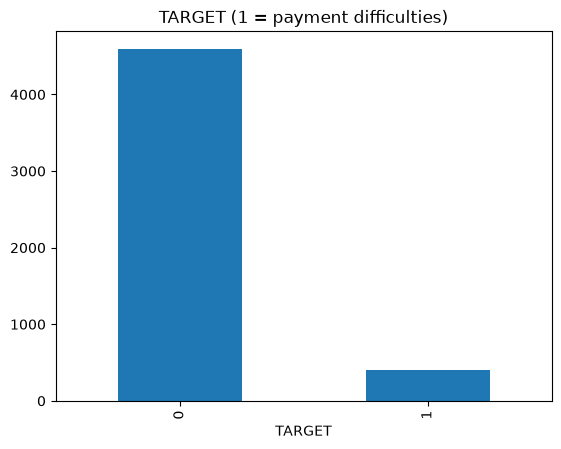

In [2]:
# PROVIDED
counts = app["TARGET"].value_counts().sort_index()
print(counts)
print(f"Default rate: {app['TARGET'].mean():.2%}")
counts.plot.bar(title="TARGET (1 = payment difficulties)")
plt.show()

## 3. Missingness  (TODO(student))

Which columns have the most missing values? How many columns are more than half empty?
Do the most-missing columns seem to belong together (look at their names)?

In [4]:
# TODO(student)
missing_pct = app.isna().mean().mul(100).sort_values(ascending=False)

print("Columns with the most missing values:")
print(missing_pct.head(15).round(2))

more_than_half = (missing_pct > 50).sum()
print(f"\nNumber of columns more than half empty: {more_than_half}")

print("\nColumns more than half empty:")
print(missing_pct[missing_pct > 50].round(2))

Columns with the most missing values:
COMMONAREA_AVG              71.42
COMMONAREA_MODE             71.42
COMMONAREA_MEDI             71.42
NONLIVINGAPARTMENTS_MEDI    71.02
NONLIVINGAPARTMENTS_MODE    71.02
NONLIVINGAPARTMENTS_AVG     71.02
LIVINGAPARTMENTS_AVG        70.16
LIVINGAPARTMENTS_MODE       70.16
LIVINGAPARTMENTS_MEDI       70.16
FONDKAPREMONT_MODE          70.08
FLOORSMIN_MODE              69.60
FLOORSMIN_AVG               69.60
FLOORSMIN_MEDI              69.60
YEARS_BUILD_AVG             68.10
YEARS_BUILD_MODE            68.10
dtype: float64

Number of columns more than half empty: 48

Columns more than half empty:
COMMONAREA_AVG                  71.42
COMMONAREA_MODE                 71.42
COMMONAREA_MEDI                 71.42
NONLIVINGAPARTMENTS_MEDI        71.02
NONLIVINGAPARTMENTS_MODE        71.02
NONLIVINGAPARTMENTS_AVG         71.02
LIVINGAPARTMENTS_AVG            70.16
LIVINGAPARTMENTS_MODE           70.16
LIVINGAPARTMENTS_MEDI           70.16
FONDKAPREMONT_MODE  

## 4. The DAYS_EMPLOYED anomaly  (TODO(student))

Look at the distribution of `DAYS_EMPLOYED`. Which value looks impossible, and how many
applicants have it? Is the default rate of those applicants different from everyone else's?
What does that tell you about how to handle it?

In [5]:
# TODO(student)
print(app["DAYS_EMPLOYED"].describe())

anomaly_value = app["DAYS_EMPLOYED"].max()
anomaly = app[app["DAYS_EMPLOYED"] == anomaly_value]
others = app[app["DAYS_EMPLOYED"] != anomaly_value]

print(f"\nAnomalous value: {anomaly_value}")
print(f"Applicants with this value: {len(anomaly)}")
print(f"Default rate for anomalous applicants: {anomaly['TARGET'].mean():.2%}")
print(f"Default rate for other applicants: {others['TARGET'].mean():.2%}")

app["DAYS_EMPLOYED"].value_counts().head(10)

count      5000.000000
mean      63622.116200
std      141057.282676
min      -15202.000000
25%       -2686.750000
50%       -1198.000000
75%        -305.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64

Anomalous value: 365243
Applicants with this value: 897
Default rate for anomalous applicants: 4.91%
Default rate for other applicants: 8.77%


DAYS_EMPLOYED
 365243    897
-1413        6
-617         6
-1152        6
-96          6
-1174        6
-209         6
-234         5
-948         5
-237         5
Name: count, dtype: int64

## 5. Default rate by a categorical column  (TODO(student))

Pick one categorical column (for example `NAME_CONTRACT_TYPE`, `CODE_GENDER`, or
`OCCUPATION_TYPE`). Show the default rate and the number of applicants in each category.
Which differences would you trust, given how few applicants some categories have?

In [6]:
# TODO(student)
default_by_category = app.groupby("NAME_CONTRACT_TYPE", observed=True).agg(
    applicants=("TARGET", "size"),
    defaults=("TARGET", "sum"),
    default_rate=("TARGET", "mean")
)

default_by_category["default_rate"] *= 100

print(default_by_category.sort_values("default_rate", ascending=False).round(2))

                    applicants  defaults  default_rate
NAME_CONTRACT_TYPE                                    
Cash loans                4525       382          8.44
Revolving loans            475        22          4.63


## 6. Correlations with TARGET  (TODO(student))

Which numeric columns are most correlated with `TARGET` (positively and negatively)?
Remember the sign conventions: `DAYS_*` columns are negative numbers of days before the
application. Is a correlation of 0.1 large or small here?

In [7]:
# TODO(student)
numeric = app.select_dtypes(include="number")
correlations = numeric.corr()["TARGET"].drop("TARGET").dropna().sort_values()

print("Most negatively correlated with TARGET:")
print(correlations.head(10).round(3))

print("\nMost positively correlated with TARGET:")
print(correlations.tail(10).sort_values(ascending=False).round(3))

Most negatively correlated with TARGET:
EXT_SOURCE_2                   -0.189
EXT_SOURCE_1                   -0.183
EXT_SOURCE_3                   -0.161
DAYS_EMPLOYED                  -0.053
AMT_GOODS_PRICE                -0.052
FLAG_PHONE                     -0.043
AMT_CREDIT                     -0.042
YEARS_BEGINEXPLUATATION_MEDI   -0.039
YEARS_BEGINEXPLUATATION_AVG    -0.039
AMT_INCOME_TOTAL               -0.038
Name: TARGET, dtype: float64

Most positively correlated with TARGET:
DAYS_BIRTH                     0.083
REG_CITY_NOT_LIVE_CITY         0.068
REG_CITY_NOT_WORK_CITY         0.067
DAYS_LAST_PHONE_CHANGE         0.059
REGION_RATING_CLIENT_W_CITY    0.058
REGION_RATING_CLIENT           0.057
FLAG_EMP_PHONE                 0.054
DAYS_REGISTRATION              0.054
DEF_60_CNT_SOCIAL_CIRCLE       0.045
OWN_CAR_AGE                    0.043
Name: TARGET, dtype: float64


## 7. Findings  (TODO(student))

Write 4 to 6 bullet points: what you learned and what it means for the baseline model.

- TODO(student)

The dataset has missing values in several columns, so the baseline model needs a strategy for handling missing data.



Some columns are more than half empty, so dropping or imputing them may improve data quality.



The DAYS_EMPLOYED column contains an unrealistic value that should be treated as missing or flagged with an indicator.



Default rates differ across contract types, so categorical features may help the model predict payment difficulties.



Numeric columns have relatively weak correlations with TARGET, so the baseline model should consider multiple features together.



The dataset may be imbalanced, so the baseline model should evaluate metrics such as precision, recall, and F1-score in addition to accuracy.